<a href="https://colab.research.google.com/github/ryifanay-wq/REGRESI_NAYLA/blob/main/NAYLA2_MATPLOTLIB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



        ANALISIS DATA FISKAL DAN PEMBANGUNAN DAERAH

5 DATA PERTAMA:
              Kota  Tahun  DBH_PAJAK  DBH_SDA  DBH_Lainnya  DAU_Grant  \
0  Kota Banda Aceh   2014      77.91    49.42        26.00      96.98   
1  Kota Banda Aceh   2015      54.88    37.29        35.35     112.77   
2  Kota Banda Aceh   2016      78.91    27.08        39.83     107.56   
3  Kota Banda Aceh   2017      72.77    26.01        46.46     109.93   
4  Kota Banda Aceh   2018      93.06    82.81        31.70     127.89   

   DAU_Earmark  DAK_Fisik  DAK_Nonfisik     PAD  ...  bm_lingkungan  \
0        47.59      83.94         72.02  153.66  ...         175.78   
1        59.88      74.74         52.84  119.84  ...          98.47   
2        52.78      96.58         97.41  179.24  ...         264.70   
3        80.91      63.84         73.98  150.55  ...         219.24   
4        60.87      77.19         80.88  148.09  ...         259.48   

   bm_ekonomi  bm_infrastruktur  bm_pariwisata  bm_perlindungan

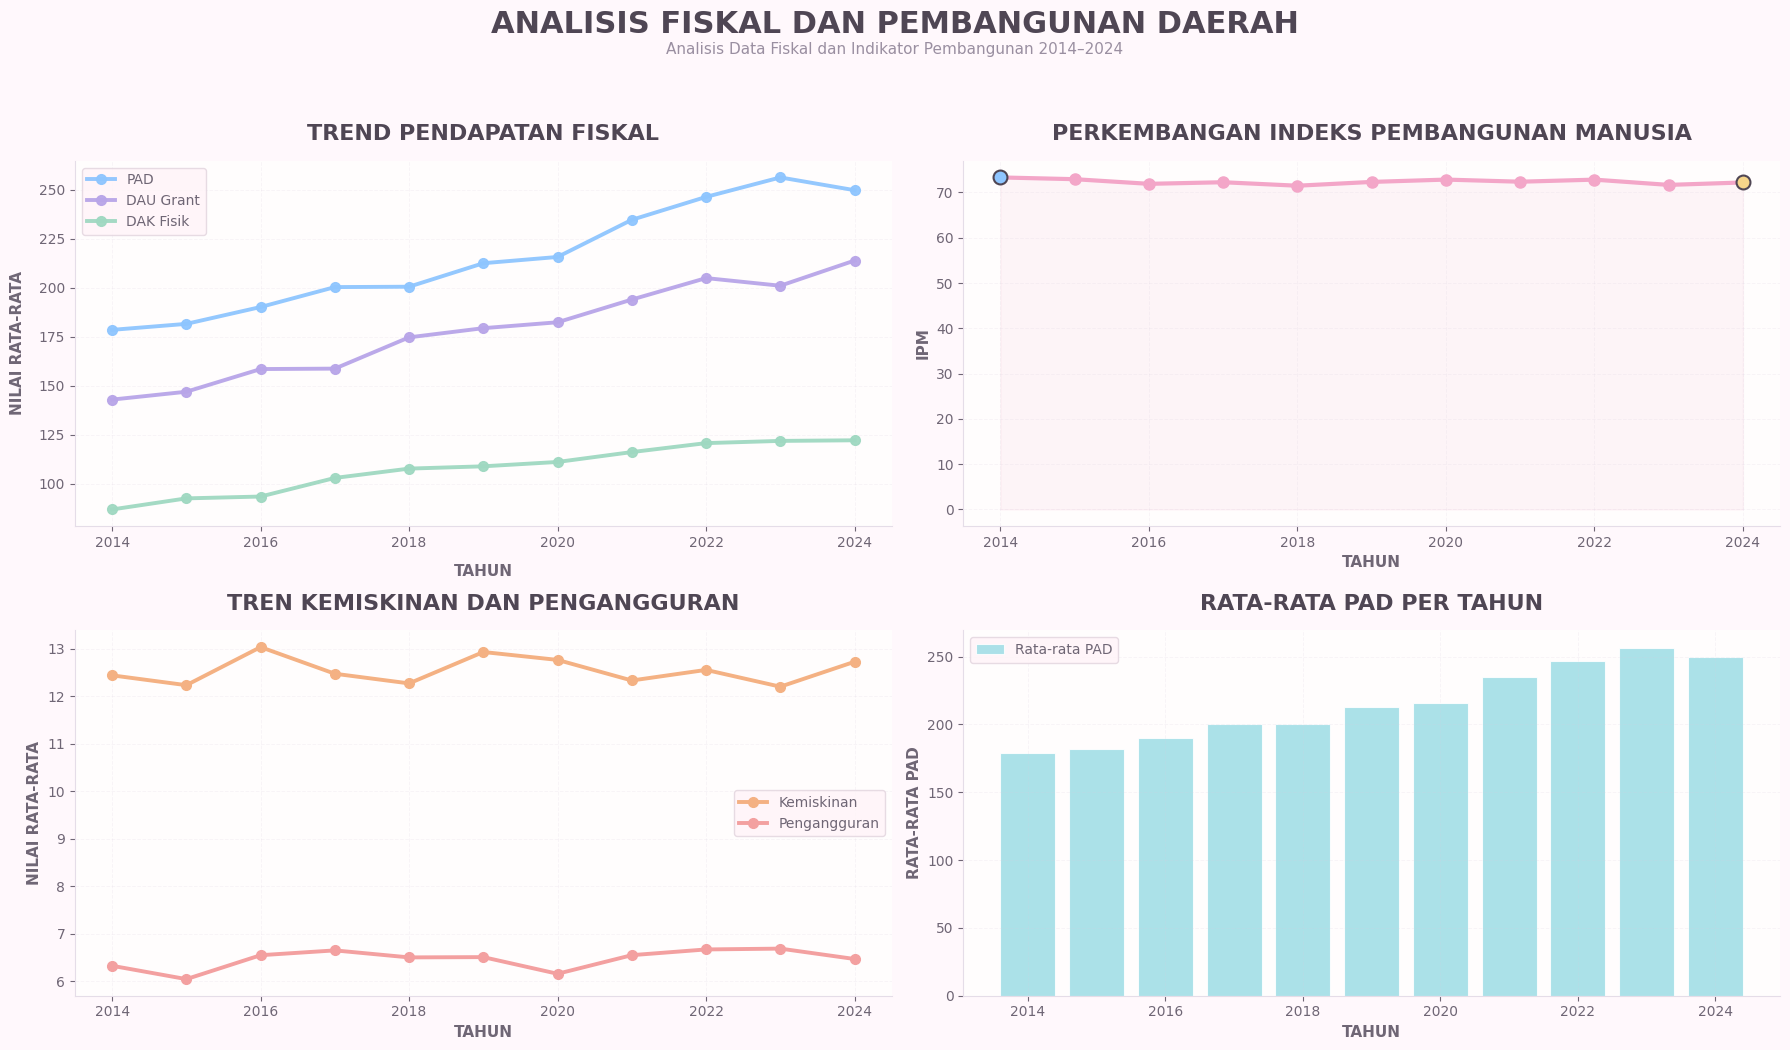



                 HASIL ANALISIS DATA

1. PERKEMBANGAN IPM
--------------------------------------------------
IPM rata-rata tahun 2014 : 73.32
IPM rata-rata tahun 2024 : 72.21
Perubahan IPM                 : -1.11
Persentase perubahan          : -1.52%
IPM tertinggi terjadi pada    : 2014 (73.32)
IPM terendah terjadi pada     : 2018 (71.49)

2. KONDISI FISKAL
--------------------------------------------------
Rata-rata PAD seluruh data    : 215.20
PAD rata-rata tertinggi       : 2023 (256.35)

3. KONDISI SOSIAL
--------------------------------------------------
Rata-rata kemiskinan          : 12.54
Rata-rata pengangguran        : 6.47
Kemiskinan tertinggi          : 2016 (13.03)
Pengangguran tertinggi        : 2023 (6.69)

4. HUBUNGAN PAD DAN IPM
--------------------------------------------------
Koefisien korelasi PAD-IPM   : -0.300


                     INTERPRETASI

• IPM mengalami penurunan rata-rata dari 73.32 menjadi 72.21.

• Hubungan PAD dan IPM relatif lemah. Perubahan PAD t

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. IMPORT DATA
# =========================================================

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"

df = pd.read_csv(url)

print("=" * 70)
print("\n\n        ANALISIS DATA FISKAL DAN PEMBANGUNAN DAERAH")
print("=" * 70)

print("\n5 DATA PERTAMA:")
print(df.head())

print("\nINFORMASI DATA:")
print(df.info())

print("\nJUMLAH KOTA :", df["Kota"].nunique())
print("TAHUN       :", df["Tahun"].min(), "-", df["Tahun"].max())
print("JUMLAH DATA :", len(df))


# =========================================================
# 2. PEMBERSIHAN DATA
# =========================================================

# Mengubah kolom tahun menjadi integer
df["Tahun"] = df["Tahun"].astype(int)

# Mengambil kolom numerik
kolom_numerik = df.select_dtypes(include=np.number).columns

# Mengubah data menjadi numerik
df[kolom_numerik] = df[kolom_numerik].apply(
    pd.to_numeric,
    errors="coerce"
)


# =========================================================
# 3. RATA-RATA NASIONAL PER TAHUN
# =========================================================

tahunan = df.groupby("Tahun").mean(numeric_only=True)


tahun = tahunan.index.to_numpy()


# Define ipm_awal and ipm_akhir
ipm_awal = tahunan["IPM"].iloc[0]
ipm_akhir = tahunan["IPM"].iloc[-1]

# Define x_clean and y_clean for correlation
x_clean = tahunan["PAD"]
y_clean = tahunan["IPM"]


# =========================================================
# 4. WARNA PASTEL
# =========================================================

biru = "#74B9FF"
pink = "#FF9FCB"
ungu = "#A78BFA"
hijau = "#70D6BE"
kuning = "#FFD166"
orange = "#FFB36B"
merah = "#FF8FA3"
abu = "#6C7293"

background = "#F8F7FF"


# =========================================================
# TEMA GRAFIK - DARK NAVY
# =========================================================

plt.style.use("default")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 11)
)

# Background utama
fig.patch.set_facecolor("#FFF8FC")

# Background setiap grafik
for ax in axes.flat:
    ax.set_facecolor("#FFFDFD")

    # Grid
    ax.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.18,
        color="#D8CFE0"
    )

    # Border
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#E5DDE8")
    ax.spines["bottom"].set_color("#E5DDE8")

    # Tulisan axis
    ax.tick_params(
        colors="#6F6675",
        labelsize=10
    )


# =========================================================
# PALET WARNA SEPERTI GAMBAR
# =========================================================

biru = "#8EC5FF"
pink = "#F3A6C8"
ungu = "#B8A5E8"
hijau = "#9FD8C1"
kuning = "#F6D58A"
orange = "#F4B183"
merah = "#F3A0A0"
cyan = "#9DDDE5"
lavender = "#C8B6E8"
hijau_muda = "#B7E4C7"

putih = "#4F4654"
abu = "#6F6675"
abu_muda = "#9A8FA1"
background = "#FFF8FC"


# =========================================================
# GRAFIK 1
# TREN PENDAPATAN FISKAL
# =========================================================

ax1 = axes[0, 0]

ax1.plot(
    tahun,
    tahunan["PAD"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=biru,
    alpha=0.95,
    label="PAD"
)

ax1.plot(
    tahun,
    tahunan["DAU_Grant"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=ungu,
    alpha=0.95,
    label="DAU Grant"
)

ax1.plot(
    tahun,
    tahunan["DAK_Fisik"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=hijau,
    alpha=0.95,
    label="DAK Fisik"
)

ax1.set_title(
    "TREND PENDAPATAN FISKAL",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax1.set_xlabel(
    "TAHUN",
    fontsize=11,
    fontweight="bold",
    color=abu,
    labelpad=10
)

ax1.set_ylabel(
    "NILAI RATA-RATA",
    fontsize=11,
    fontweight="bold",
    color=abu,
    labelpad=10
)

ax1.legend(
    frameon=True,
    facecolor="#FFF4F8",
    edgecolor="#E2D4DE",
    labelcolor=abu
)


# =========================================================
# GRAFIK 2
# TREN IPM
# =========================================================

ax2 = axes[0, 1]

ax2.plot(
    tahun,
    tahunan["IPM"],
    marker="o",
    markersize=8,
    linewidth=3,
    color=pink,
    label="IPM"
)

ax2.fill_between(
    tahun,
    tahunan["IPM"],
    alpha=0.10,
    color=pink
)

# Titik awal
ax2.scatter(
    tahun[0],
    ipm_awal,
    s=100,
    color=biru,
    edgecolors=putih,
    linewidth=1.5,
    zorder=5
)

# Titik akhir
ax2.scatter(
    tahun[-1],
    ipm_akhir,
    s=100,
    color=kuning,
    edgecolors=putih,
    linewidth=1.5,
    zorder=5
)

ax2.set_title(
    "PERKEMBANGAN INDEKS PEMBANGUNAN MANUSIA",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax2.set_xlabel(
    "TAHUN",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax2.set_ylabel(
    "IPM",
    fontsize=11,
    fontweight="bold",
    color=abu
)


# =========================================================
# GRAFIK 3
# KEMISKINAN DAN PENGANGGURAN
# =========================================================

ax3 = axes[1, 0]

ax3.plot(
    tahun,
    tahunan["KEMISKINAN"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=orange,
    label="Kemiskinan"
)

ax3.plot(
    tahun,
    tahunan["PENGANGGURAN"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=merah,
    label="Pengangguran"
)

ax3.set_title(
    "TREN KEMISKINAN DAN PENGANGGURAN",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax3.set_xlabel(
    "TAHUN",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax3.set_ylabel(
    "NILAI RATA-RATA",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax3.legend(
    frameon=True,
    facecolor="#FFF4F8",
    edgecolor="#E2D4DE",
    labelcolor=abu
)


# =========================================================
# GRAFIK 4
# HUBUNGAN PAD DAN IPM
# =========================================================

ax4 = axes[1, 1]

# Bar chart rata-rata PAD per tahun
ax4.bar(
    tahun,
    tahunan["PAD"],
    color=cyan,
    alpha=0.85,
    edgecolor="#FFFFFF",
    linewidth=0.8,
    label="Rata-rata PAD"
)

ax4.set_title(
    "RATA-RATA PAD PER TAHUN",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax4.set_xlabel(
    "TAHUN",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax4.set_ylabel(
    "RATA-RATA PAD",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax4.legend(
    frameon=True,
    facecolor="#FFF4F8",
    edgecolor="#E2D4DE",
    labelcolor=abu
)


# =========================================================
# JUDUL UTAMA
# =========================================================

fig.suptitle(
    "ANALISIS FISKAL DAN PEMBANGUNAN DAERAH",
    fontsize=22,
    fontweight="bold",
    color=putih,
    y=0.98
)

fig.text(
    0.5,
    0.94,
    "Analisis Data Fiskal dan Indikator Pembangunan 2014–2024",
    ha="center",
    fontsize=11,
    color=abu_muda
)


# =========================================================
# LAYOUT
# =========================================================

plt.tight_layout(
    rect=[0, 0.03, 1, 0.93]
)

plt.show()


# =========================================================
# 8. ANALISIS MENGGUNAKAN NUMPY
# =========================================================

# Perubahan IPM
perubahan_ipm = ipm_akhir - ipm_awal

persen_ipm = (
    perubahan_ipm / ipm_awal
) * 100


# Rata-rata PAD
rata_pad = np.mean(df["PAD"])

# Rata-rata kemiskinan
rata_kemiskinan = np.mean(
    df["KEMISKINAN"]
)

# Rata-rata pengangguran
rata_pengangguran = np.mean(
    df["PENGANGGURAN"]
)


# =========================================================
# 9. KORELASI PAD DAN IPM
# =========================================================

korelasi_pad_ipm = np.corrcoef(
    x_clean,
    y_clean
)[0, 1]


# =========================================================
# 10. NILAI TERTINGGI DAN TERENDAH
# =========================================================

tahun_ipm_tertinggi = tahunan["IPM"].idxmax()
nilai_ipm_tertinggi = tahunan["IPM"].max()

tahun_ipm_terendah = tahunan["IPM"].idxmin()
nilai_ipm_terendah = tahunan["IPM"].min()


tahun_pad_tertinggi = tahunan["PAD"].idxmax()
nilai_pad_tertinggi = tahunan["PAD"].max()


tahun_kemiskinan_tertinggi = (
    tahunan["KEMISKINAN"].idxmax()
)

nilai_kemiskinan_tertinggi = (
    tahunan["KEMISKINAN"].max()
)


tahun_pengangguran_tertinggi = (
    tahunan["PENGANGGURAN"].idxmax()
)

nilai_pengangguran_tertinggi = (
    tahunan["PENGANGGURAN"].max()
)


# =========================================================
# 11. HASIL ANALISIS
# =========================================================

print("\n")
print("=" * 70)
print("                 HASIL ANALISIS DATA")
print("=" * 70)


print("\n1. PERKEMBANGAN IPM")
print("-" * 50)

print(
    f"IPM rata-rata tahun {tahun[0]} : "
    f"{ipm_awal:.2f}"
)

print(
    f"IPM rata-rata tahun {tahun[-1]} : "
    f"{ipm_akhir:.2f}"
)

print(
    f"Perubahan IPM                 : "
    f"{perubahan_ipm:.2f}"
)

print(
    f"Persentase perubahan          : "
    f"{persen_ipm:.2f}%"
)

print(
    f"IPM tertinggi terjadi pada    : "
    f"{tahun_ipm_tertinggi} "
    f"({nilai_ipm_tertinggi:.2f})"
)

print(
    f"IPM terendah terjadi pada     : "
    f"{tahun_ipm_terendah} "
    f"({nilai_ipm_terendah:.2f})"
)


print("\n2. KONDISI FISKAL")
print("-" * 50)

print(
    f"Rata-rata PAD seluruh data    : "
    f"{rata_pad:.2f}"
)

print(
    f"PAD rata-rata tertinggi       : "
    f"{tahun_pad_tertinggi} "
    f"({nilai_pad_tertinggi:.2f})"
)


print("\n3. KONDISI SOSIAL")
print("-" * 50)

print(
    f"Rata-rata kemiskinan          : "
    f"{rata_kemiskinan:.2f}"
)

print(
    f"Rata-rata pengangguran        : "
    f"{rata_pengangguran:.2f}"
)

print(
    f"Kemiskinan tertinggi          : "
    f"{tahun_kemiskinan_tertinggi} "
    f"({nilai_kemiskinan_tertinggi:.2f})"
)

print(
    f"Pengangguran tertinggi        : "
    f"{tahun_pengangguran_tertinggi} "
    f"({nilai_pengangguran_tertinggi:.2f})"
)


print("\n4. HUBUNGAN PAD DAN IPM")
print("-" * 50)

print(
    f"Koefisien korelasi PAD-IPM   : "
    f"{korelasi_pad_ipm:.3f}"
)


# =========================================================
# 12. INTERPRETASI OTOMATIS
# =========================================================

print("\n")
print("=" * 70)
print("                     INTERPRETASI")
print("=" * 70)


# Interpretasi IPM

if perubahan_ipm > 0:
    print(
        f"\n• IPM menunjukkan kecenderungan meningkat "
        f"dari {ipm_awal:.2f} pada {tahun[0]} "
        f"menjadi {ipm_akhir:.2f} pada {tahun[-1]}. "
        f"Hal ini menunjukkan adanya peningkatan rata-rata "
        f"indikator pembangunan manusia selama periode pengamatan."
    )
else:
    print(
        f"\n• IPM mengalami penurunan rata-rata "
        f"dari {ipm_awal:.2f} menjadi {ipm_akhir:.2f}."
    )


# Interpretasi korelasi

if korelasi_pad_ipm > 0.7:

    print(
        "\n• Hubungan PAD dan IPM memiliki korelasi positif "
        "yang relatif kuat. Dalam data ini, daerah dengan "
        "PAD yang lebih tinggi cenderung memiliki nilai IPM "
        "yang lebih tinggi."
    )

elif korelasi_pad_ipm > 0.3:

    print(
        "\n• Hubungan PAD dan IPM menunjukkan korelasi positif "
        "tingkat sedang. Artinya, peningkatan PAD dalam "
        "data cenderung berjalan bersama dengan nilai IPM "
        "yang lebih tinggi."
    )

elif korelasi_pad_ipm > -0.3:

    print(
        "\n• Hubungan PAD dan IPM relatif lemah. "
        "Perubahan PAD tidak menunjukkan hubungan linear "
        "yang kuat dengan IPM dalam dataset ini."
    )

else:

    print(
        "\n• Hubungan PAD dan IPM menunjukkan korelasi negatif. "
        "Dalam dataset ini, nilai PAD yang lebih tinggi "
        "cenderung berkaitan dengan nilai IPM yang lebih rendah."
    )


# Interpretasi kemiskinan

print(
    f"\n• Rata-rata kemiskinan seluruh observasi adalah "
    f"{rata_kemiskinan:.2f}, sedangkan rata-rata "
    f"pengangguran adalah {rata_pengangguran:.2f}."
)


# Interpretasi fiskal

print(
    f"\n• Perkembangan PAD, DAU Grant, dan DAK Fisik "
    f"dapat digunakan untuk melihat perubahan kapasitas "
    f"dan dukungan fiskal daerah dari waktu ke waktu."
)


print(
    "\n• Hubungan statistik yang ditampilkan pada grafik "
    "tidak secara otomatis menunjukkan hubungan sebab-akibat. "
    "Korelasi hanya menunjukkan pola hubungan dalam data."
)


print("\n" + "=" * 70)
print("                 ANALISIS SELESAI")
print("=" * 70)